# Loan Default Risk: Modeling

# Importing packages

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import roc_curve
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

## Connecting to the database

In [2]:
load_dotenv(find_dotenv()) 

url = URL.create(
    "postgresql+psycopg2",
    username=os.environ["PGUSER"],
    password=os.environ["PGPASSWORD"],
    host=os.environ["PGHOST"],
    port=int(os.environ["PGPORT"]),
    database=os.environ["PGDATABASE"],
)
engine = create_engine(url)

## Loading data from database

In [3]:
df = pd.read_sql("SELECT * FROM customer_features", engine)
df.shape

(307511, 29)

## Data quality checks

In [4]:
display(df.dtypes)
display(df.isna().mean().sort_values(ascending=False).head(10))

sk_id_curr                   int64
target                       int64
name_contract_type             str
code_gender                    str
name_education_type            str
name_income_type               str
amt_income_total           float64
amt_credit                 float64
amt_annuity                float64
age_years                  float64
years_employed             float64
credit_to_income           float64
annuity_to_income          float64
ext_source_1               float64
ext_source_2               float64
ext_source_3               float64
n_bureau_credits             int64
n_bureau_active              int64
bureau_max_days_overdue    float64
bureau_debt_ratio          float64
n_prev_apps                  int64
n_prev_approved              int64
n_prev_refused               int64
prev_refused_share         float64
n_installments               int64
inst_avg_delay_days        float64
inst_underpaid_share       float64
cc_avg_utilization         float64
pos_max_dpd         

cc_avg_utilization         0.720218
ext_source_1               0.563811
bureau_debt_ratio          0.338294
ext_source_3               0.198253
years_employed             0.180072
bureau_max_days_overdue    0.143149
pos_max_dpd                0.058752
prev_refused_share         0.053507
inst_avg_delay_days        0.051627
inst_underpaid_share       0.051601
dtype: float64

**Findings:** the dataset has 307,511 clients and 29 columns. The target is strongly imbalanced: 91.9% of clients repaid and 8.1% defaulted. Accuracy alone would therefore be misleading (a model predicting "no default" for everyone would be 92% accurate), so the models are compared with AUC, precision and recall, and the training uses balanced class weights.

## Exploratory analysis
External scores and a correlation overview, to check in what the SQL analysis suggested.

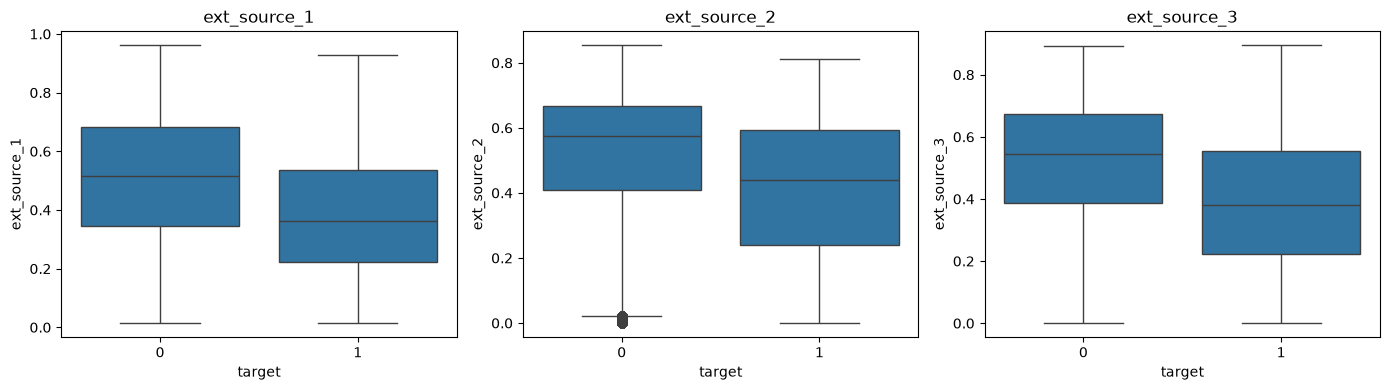

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["ext_source_1", "ext_source_2", "ext_source_3"]):
    sns.boxplot(data=df, x="target", y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

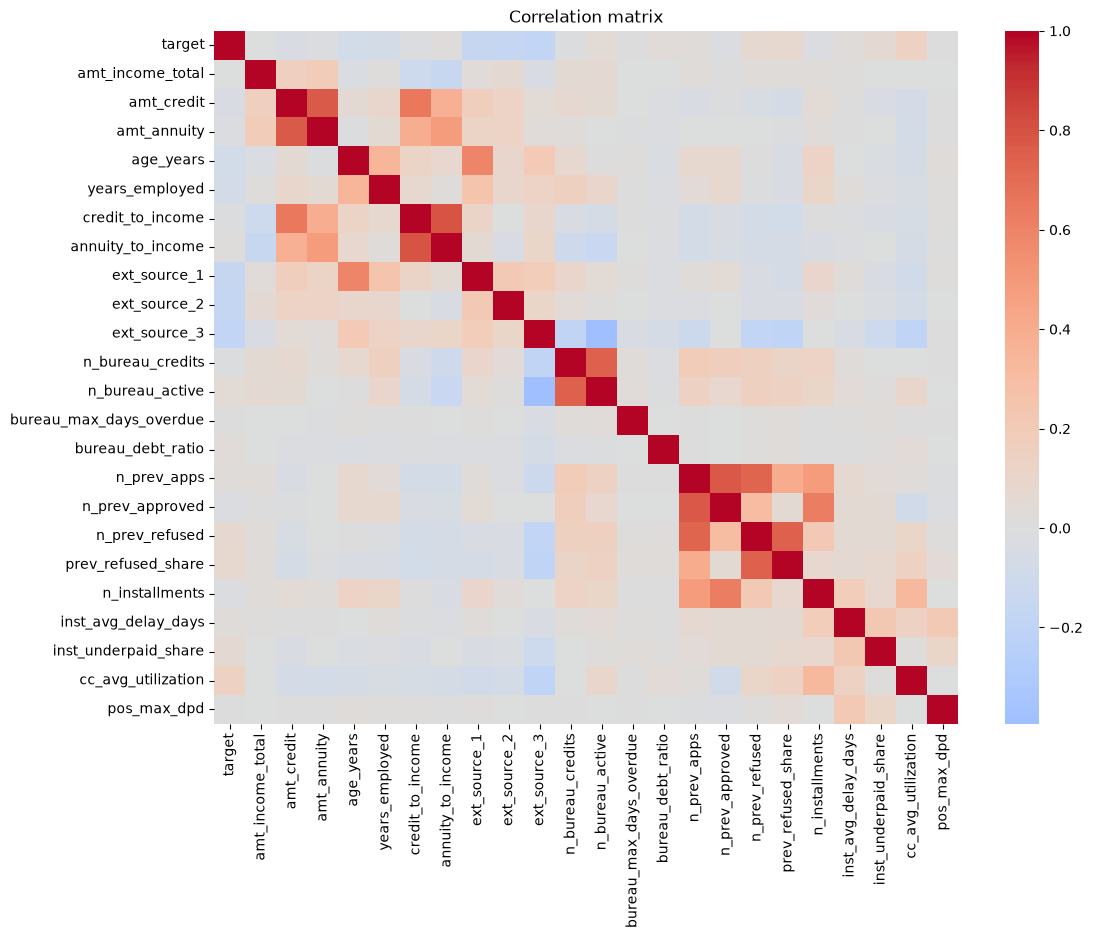

In [6]:
num_df = df.select_dtypes("number").drop(columns="sk_id_curr")
plt.figure(figsize=(12, 9))
sns.heatmap(num_df.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation matrix")
plt.show()

**Findings:** the external scores (ext_source_1/2/3) are the variables that separate the two classes most clearly, with lower scores among defaulting clients, consistent with the negative correlations found in the SQL analysis. Linear relationships between individual features and the target are generally weak, so the signal is expected to come from combining many features rather than from a single variable.

## Data Cleaning
- Remove the few rows with unknown gender (XNA).
- Clip extreme values (0.1% / 99.9% quantiles) in amount and ratio columns.
- Missing values are kept as they are: they are imputed later, inside the model pipeline.

In [7]:
df = df[df["code_gender"] != "XNA"].copy()

clip_cols = ["amt_income_total", "amt_credit", "amt_annuity", "credit_to_income",
             "annuity_to_income", "bureau_debt_ratio", "cc_avg_utilization",
             "inst_avg_delay_days"]
for c in clip_cols:
    lo, hi = df[c].quantile([0.001, 0.999])
    df[c] = df[c].clip(lo, hi)

df.shape

(307507, 29)

**Findings:** 4 clients with unknown gender (XNA) were removed, leaving 307,507 rows. Extreme values in eight amount and ratio columns were clipped at the 0.1% and 99.9% quantiles to limit their influence on the models. Missing values are intentionally kept: logistic regression imputes them with the median (plus a missing-value indicator), while LightGBM handles them natively.

## Model Preparation
Features/target split and a stratified train/test split (the target is imbalanced, ~8% defaults).

In [8]:
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, RocCurveDisplay, classification_report, ConfusionMatrixDisplay

cat_cols = ["name_contract_type", "code_gender", "name_education_type", "name_income_type"]

X = df.drop(columns=["sk_id_curr", "target"])
y = df["target"]
num_cols = [c for c in X.columns if c not in cat_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape, y_train.mean().round(4), y_test.mean().round(4))

(246005, 27) (61502, 27) 0.0807 0.0807


## Baseline Model: Logistic Regression
Median imputation (with missing-value indicators, since "no history" is informative),
scaling, one-hot encoding and balanced class weights.

In [9]:
preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

logreg = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
logreg.fit(X_train, y_train)

p_logreg = logreg.predict_proba(X_test)[:, 1]
print(f"Logistic regression AUC: {roc_auc_score(y_test, p_logreg):.3f}")

Logistic regression AUC: 0.756


## Gradient Boosting: LightGBM
Handles missing values and non-linear effects natively. Early stopping uses a validation
set carved out of the training data, so the test set stays untouched.

In [10]:
X_lgb = X.copy()
X_lgb[cat_cols] = X_lgb[cat_cols].astype("category")
Xtr_all, Xte = X_lgb.loc[X_train.index], X_lgb.loc[X_test.index]

Xtr, Xval, ytr, yval = train_test_split(
    Xtr_all, y_train, test_size=0.2, stratify=y_train, random_state=42
)

lgbm = lgb.LGBMClassifier(
    n_estimators=1000, learning_rate=0.05, num_leaves=31,
    class_weight="balanced", random_state=42, n_jobs=-1, verbose=-1,
)
lgbm.fit(
    Xtr, ytr,
    eval_set=[(Xval, yval)], eval_metric="auc",
    callbacks=[lgb.early_stopping(50, verbose=False)],
)

p_lgbm = lgbm.predict_proba(Xte)[:, 1]
print(f"LightGBM AUC: {roc_auc_score(y_test, p_lgbm):.3f} (best iteration: {lgbm.best_iteration_})")

d:\projects\loan-default-risk-analysis\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM AUC: 0.765 (best iteration: 161)


## Model Evaluation
AUC and ROC curves for both models, then precision/recall and the confusion matrix
for LightGBM at a 0.5 threshold. Accuracy alone is misleading with ~8% defaults.

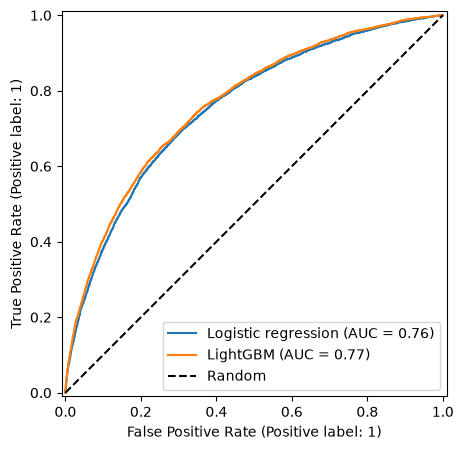

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, p_logreg, name="Logistic regression", ax=ax)
RocCurveDisplay.from_predictions(y_test, p_lgbm, name="LightGBM", ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random")
ax.legend()
plt.show()

              precision    recall  f1-score   support

           0      0.962     0.713     0.819     56537
           1      0.172     0.679     0.274      4965

    accuracy                          0.710     61502
   macro avg      0.567     0.696     0.547     61502
weighted avg      0.898     0.710     0.775     61502



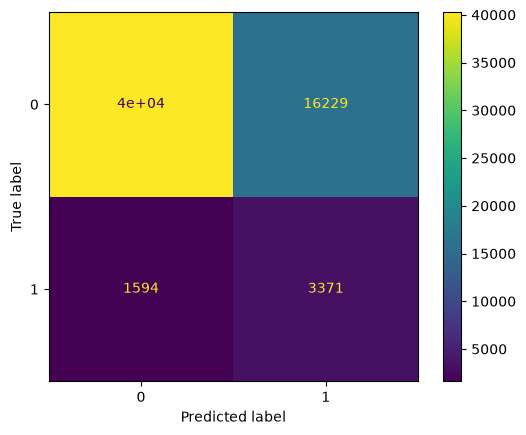

In [12]:
pred = (p_lgbm >= 0.5).astype(int)
print(classification_report(y_test, pred, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.show()

**Findings:** both models rank clients well on unseen data: logistic regression reaches an AUC of 0.758 and LightGBM 0.766. The small gap suggests that non-linear effects add only a little on top of the engineered features, so the simple model is a strong baseline.

At the default 0.5 threshold, LightGBM catches 68.4% of the defaults (recall) but only 17.6% of the clients flagged are real defaults (precision). This is expected with ~8% defaults and balanced class weights: roughly 3,400 of the 4,965 defaulting clients in the test set are caught, at the cost of about 15,900 good clients flagged. The 0.5 threshold is only a default; the right cut-off depends on the business trade-off analysed in the scenario below.

## Model Interpretation
Logistic regression coefficients (direction of the effect) and LightGBM feature importance
(gain), compared with the correlations found in the SQL analysis.

In [13]:
names = logreg.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(logreg.named_steps["model"].coef_[0], index=names)
coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)

num__ext_source_2                            -0.419472
num__ext_source_3                            -0.395185
cat__name_education_type_Higher education    -0.290239
cat__name_contract_type_Revolving loans      -0.260835
cat__code_gender_F                           -0.235274
cat__name_education_type_Lower secondary      0.228032
num__n_bureau_active                          0.227524
num__ext_source_1                            -0.215649
cat__name_education_type_Incomplete higher   -0.188577
num__cc_avg_utilization                       0.173860
num__years_employed                          -0.168082
num__inst_underpaid_share                     0.164831
cat__name_income_type_State servant          -0.158024
num__bureau_debt_ratio                        0.121538
num__n_bureau_credits                        -0.120897
dtype: float64

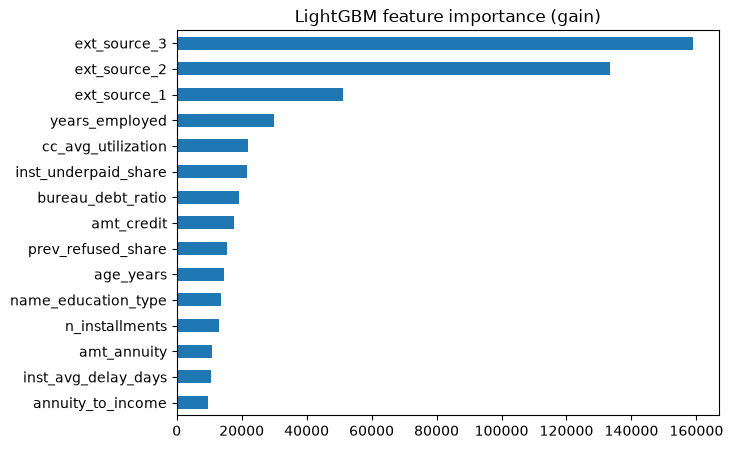

In [14]:
imp = pd.Series(
    lgbm.booster_.feature_importance(importance_type="gain"), index=Xtr.columns
).sort_values().tail(15)
imp.plot.barh(figsize=(7, 5), title="LightGBM feature importance (gain)")
plt.show()

**Findings:** in the logistic regression (standardized features, so coefficients are comparable), the strongest effects come from the external scores: ext_source_2 (-0.42) and ext_source_3 (-0.40) reduce default risk the most, followed by higher education (-0.29), revolving loans (-0.26) and ext_source_1 (-0.20). Risk increases with credit card utilization (+0.18), the share of underpaid installments (+0.17), the bureau debt ratio (+0.12) and the number of active credits (+0.23). This agrees with the correlations found in the SQL analysis.

n_bureau_active (+) and n_bureau_credits (-) have opposite signs, most likely because the two features are correlated, so they should not be interpreted separately.

Gender (female: -0.23) is also predictive here, but it should not be used directly in real credit decisions because of regulatory and fairness concerns.

In LightGBM (feature importance by gain), the three external scores dominate: ext_source_3 and ext_source_2 are by far the most important, followed by ext_source_1. They are followed, at a clear distance, by years_employed, the share of underpaid installments (inst_underpaid_share), credit card utilization (cc_avg_utilization) and the bureau debt ratio (bureau_debt_ratio). The ranking is consistent with the logistic regression and with the SQL analysis: external scores first, then employment length and payment behavior.

Some features matter more here than in the logistic regression: the credit amount (amt_credit), age, the number of installments and the annuity. This suggests non-linear effects or interactions that the linear model cannot capture, which explains the small AUC gain of LightGBM. Importance by gain shows how much a feature contributes to the model, not the direction of its effect, so the signs come from the logistic regression coefficients.

## Business Scenario
If the bank rejected the riskiest clients according to the model score, how many defaults
would it avoid, and how many good clients would it lose?

In [15]:
scores = pd.DataFrame({"y": y_test.values, "p": p_lgbm})

rows = []
for share in [0.05, 0.10, 0.20, 0.30]:
    rejected = scores["p"] >= scores["p"].quantile(1 - share)
    rows.append({
        "rejected_share": f"{share:.0%}",
        "defaults_avoided_pct": round(100 * scores.loc[rejected, "y"].sum() / scores["y"].sum(), 1),
        "good_clients_lost_pct": round(100 * (rejected & (scores["y"] == 0)).sum() / (scores["y"] == 0).sum(), 1),
        "default_rate_rejected_pct": round(100 * scores.loc[rejected, "y"].mean(), 1),
        "default_rate_approved_pct": round(100 * scores.loc[~rejected, "y"].mean(), 1),
    })
pd.DataFrame(rows)

,rejected_share,defaults_avoided_pct,good_clients_lost_pct,default_rate_rejected_pct,default_rate_approved_pct
0,5%,21.3,3.6,34.5,6.7
1,10%,35.0,7.8,28.2,5.8
2,20%,53.8,17.0,21.7,4.7
3,30%,66.2,26.8,17.8,3.9


**Findings:** the model score can be used to reject the riskiest applicants. Rejecting the riskiest 10% of clients avoids 35.3% of all defaults while losing only 7.8% of the good clients; the default rate is 28.5% among rejected clients versus 5.8% among approved ones (overall: 8.1%).

Returns diminish as the cut-off becomes stricter: going from 10% to 20% rejected avoids 18.4 more percentage points of defaults at the cost of 9.2 points of good clients, while going from 20% to 30% adds only 13.1 points for 9.8 points lost. 

These figures do not include the interest income lost on rejected good clients or the loss amount per default, so the final threshold should be chosen by comparing those two costs.

## Export for the Dashboard
Out-of-fold risk scores for all clients (5-fold cross-validation), so every score comes
from a model that did not see that client. Saved to PostgreSQL as customer_scores.

In [16]:
lgbm_cv = lgb.LGBMClassifier(
    n_estimators=lgbm.best_iteration_, learning_rate=0.05, num_leaves=31,
    class_weight="balanced", random_state=42, n_jobs=-1, verbose=-1,
)
oof = cross_val_predict(
    lgbm_cv, X_lgb, y,
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    method="predict_proba",
)[:, 1]

customer_scores = pd.DataFrame({
    "sk_id_curr": df["sk_id_curr"].values,
    "target": y.values,
    "risk_score": oof,
})
customer_scores["risk_group"] = pd.qcut(
    customer_scores["risk_score"], 5,
    labels=["1 - Lowest risk", "2 - Low", "3 - Medium", "4 - High", "5 - Highest risk"],
)

customer_scores.to_sql("customer_scores", engine, if_exists="replace", index=False)
customer_scores.groupby("risk_group", observed=True)["target"].agg(["count", "mean"])

,count,mean
risk_group,,
1 - Lowest risk,61502,0.015804
2 - Low,61501,0.031105
3 - Medium,61501,0.051463
4 - High,61501,0.090503
5 - Highest risk,61502,0.214774


**Findings:** the out-of-fold risk scores split clients into five groups of ~61,500 each, with a default rate that increases steadily from 1.6% (lowest risk) to 21.6% (highest risk), almost 14 times higher. This shows that the model orders clients consistently by risk. The scores come from a model trained with balanced class weights, so they are a ranking score, not calibrated default probabilities. The table `customer_scores` is used in the dashboard.

In [17]:
out = Path.cwd().parent / "modeling_exports"
out.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, p_logreg, name="Logistic regression", ax=ax)
RocCurveDisplay.from_predictions(y_test, p_lgbm, name="LightGBM", ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random")
ax.legend()
fig.savefig(out / "roc_curve.png", dpi=200, bbox_inches="tight")
plt.close(fig)

roc_rows = []
for name, p in [("Logistic regression", p_logreg), ("LightGBM", p_lgbm)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    roc_rows.append(pd.DataFrame({"model": name, "fpr": fpr, "tpr": tpr}))
pd.concat(roc_rows).to_csv(out / "roc_points.csv", index=False)

pd.DataFrame({
    "model": ["Logistic regression", "LightGBM"],
    "auc": [roc_auc_score(y_test, p_logreg), roc_auc_score(y_test, p_lgbm)],
}).round(3).to_csv(out / "model_metrics.csv", index=False)

(pd.Series(lgbm.booster_.feature_importance(importance_type="gain"), index=Xtr.columns)
   .sort_values(ascending=False)
   .rename("gain").rename_axis("feature").reset_index()
   .to_csv(out / "feature_importance.csv", index=False))

(coefs.rename("coefficient").rename_axis("feature").reset_index()
      .assign(abs_coef=lambda d: d["coefficient"].abs())
      .sort_values("abs_coef", ascending=False)
      .to_csv(out / "logreg_coefficients.csv", index=False))

rows = []
for share in np.arange(0.01, 0.51, 0.01):
    rejected = scores["p"] >= scores["p"].quantile(1 - share)
    rows.append({
        "rejected_share_pct": round(share * 100),
        "defaults_avoided_pct": 100 * scores.loc[rejected, "y"].sum() / scores["y"].sum(),
        "good_clients_lost_pct": 100 * (rejected & (scores["y"] == 0)).sum() / (scores["y"] == 0).sum(),
        "default_rate_rejected_pct": 100 * scores.loc[rejected, "y"].mean(),
        "default_rate_approved_pct": 100 * scores.loc[~rejected, "y"].mean(),
    })
pd.DataFrame(rows).round(1).to_csv(out / "business_scenario.csv", index=False)

## Key Takeaways
- Default is rare (~8%), so models are judged with AUC, precision and recall, not accuracy.
- LightGBM (AUC 0.766) performs slightly better than logistic regression (AUC 0.758); both are solid with features built entirely in SQL.
- External scores, education, credit card utilization and payment behavior (underpaid installments) are the main risk drivers.
- Rejecting the riskiest 10% of applicants avoids about 35% of defaults while losing under 8% of good clients.
- The five risk groups separate clients clearly (1.6% to 21.6% default rate) and feed the dashboard.